# An early-warning system: how soon can we spot students who won't complete?

A tutor can only help a struggling student if they know **in time**. This notebook builds and evaluates an early-warning model the way it would actually be used:
1. An honest setup: snapshots in time, and training on last year to predict this year
2. Which outcome should we predict: withdrawal, or not completing?
3. How early can we know?
4. What would a tutor actually see?
5. What drives the predictions?
6. Does it work on a course it has never seen?
7. Is it fair across groups of students?

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import style
from features import ACTIVITY, ASSESSMENT, BACKGROUND, CATEGORICAL, snapshot
style.apply()

FIG = ROOT / "figures"
def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=120)

FEATURE_SETS = {
    "Background only": BACKGROUND,
    "Background + online activity": BACKGROUND + ACTIVITY,
    "Background + activity + assessments": BACKGROUND + ACTIVITY + ASSESSMENT,
}
DAYS = [0, 14, 28, 42, 56, 84, 112, 168]

def model(numeric):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
        ("num", "passthrough", numeric),
    ])
    return make_pipeline(prep, HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0))

def get_snapshot(day):
    """Students enrolled on `day` (already registered, not yet withdrawn), with both possible targets."""
    s = snapshot(day)
    s = s[s["date_registration"].isna() | (s["date_registration"] <= day)].copy()
    s["not_completed"] = s["final_result"].isin(["Fail", "Withdrawn"]).astype(int)
    s["train"] = s["year"] == 2013
    return s

## 1. An honest setup

**Snapshots in time.** For a given day of the course (day 0 = start, day 28 = end of week 4, and so on), we build features using **only what was known on that day**:
- background (deprivation band, prior education, age, disability, previous attempts, credits, how early they registered);
- online activity up to that day: total clicks, active days, clicks in the last 7 days, days since last login, clicks by type of material, and activity relative to classmates;
- assessments due by that day: submitted, missed, late, average score.

Students who **already withdrew** by that day are dropped (there is nothing left to predict), and so are students who **hadn't registered yet**.

**Train on last year, predict this year.** Models are trained on the **2013** presentations and tested on **2014**. Module **CCC** only ran in 2014, so for it the model is predicting a course it has never seen.

In [2]:
snapshots = {day: get_snapshot(day) for day in DAYS}
pd.DataFrame({day: {"students enrolled": len(s), "train (2013)": s["train"].sum(), "test (2014)": (~s["train"]).sum(),
                    "% not completing (test)": round(s.loc[~s["train"], "not_completed"].mean() * 100, 1),
                    "% withdrawing (test)": round(s.loc[~s["train"], "withdrawn"].mean() * 100, 1)}
              for day, s in snapshots.items()}).T

,students enrolled,train (2013),test (2014),% not completing (test),% withdrawing (test)
0,29262.0,12238.0,17024.0,48.7,26.6
14,28061.0,12076.0,15985.0,44.9,21.2
28,27522.0,11802.0,15720.0,43.9,19.7
42,27012.0,11614.0,15398.0,42.8,18.0
56,26513.0,11426.0,15087.0,41.6,16.4
84,25720.0,11131.0,14589.0,39.6,13.5
112,24930.0,10775.0,14155.0,37.7,10.8
168,23559.0,10244.0,13315.0,33.8,5.2


## 2. Which outcome should we predict?

Notebook 01 showed that many disengaged students never formally withdraw: they stop logging in and **fail**. We compare two targets:
- **Withdrawal**: the student formally unregisters.
- **Not completing**: the student withdraws **or** fails.

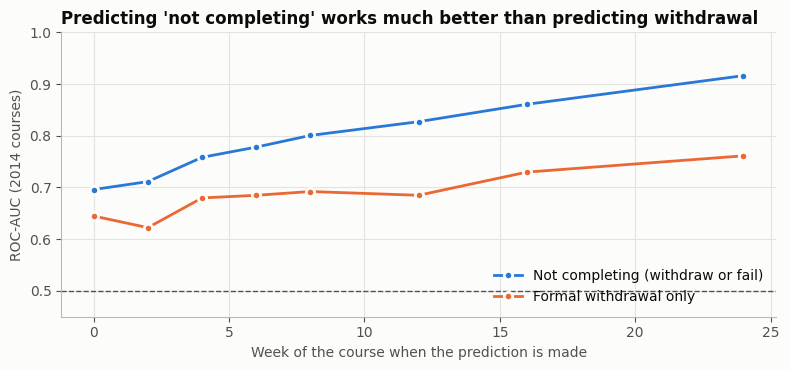

target,not_completed,withdrawn
day,,
0,0.696,0.645
14,0.711,0.622
28,0.758,0.680
42,0.778,0.685
56,0.801,0.692
84,0.827,0.685
112,0.861,0.730
168,0.916,0.761


In [3]:
rows, preds = [], {}
for day, s in snapshots.items():
    tr, te = s["train"].to_numpy(), ~s["train"].to_numpy()
    for target in ["withdrawn", "not_completed"]:
        for name, cols in FEATURE_SETS.items():
            if target == "withdrawn" and name != "Background + activity + assessments":
                continue
            y = s[target].to_numpy()
            p = model(cols).fit(s[tr], y[tr]).predict_proba(s[te])[:, 1]
            rows.append({"day": day, "target": target, "features": name, "ROC-AUC": roc_auc_score(y[te], p),
                         "AP": average_precision_score(y[te], p), "base rate": y[te].mean()})
            if target == "not_completed" and name == "Background + activity + assessments":
                preds[day] = pd.Series(p, index=s.index[te])
results = pd.DataFrame(rows)

full = results[results["features"] == "Background + activity + assessments"].pivot(index="day", columns="target", values="ROC-AUC")
fig, ax = plt.subplots(figsize=(8, 3.8))
weeks = full.index / 7
ax.plot(weeks, full["not_completed"], marker="o", color=style.BLUE, label="Not completing (withdraw or fail)",
        markeredgecolor=style.SURFACE, markeredgewidth=2)
ax.plot(weeks, full["withdrawn"], marker="o", color=style.ORANGE, label="Formal withdrawal only",
        markeredgecolor=style.SURFACE, markeredgewidth=2)
ax.axhline(0.5, color=style.TEXT_2, lw=1, ls="--")
ax.set(ylim=(0.45, 1), xlabel="Week of the course when the prediction is made", ylabel="ROC-AUC (2014 courses)",
       title="Predicting 'not completing' works much better than predicting withdrawal")
ax.legend(loc="lower right")
save_fig("06_target_choice")
plt.show()
full.round(3)

Predicting **formal withdrawal** is surprisingly hard, and it barely improves as the course goes on. Many students who stop engaging never formally withdraw: they fail instead, and the model is penalised for flagging them.
Predicting **not completing** is much easier, and the gap grows over time.
**For a tutor this is also the more useful question**: a student who silently fails needs help just as much as one who formally leaves. From here on we predict *not completing*.

## 3. How early can we know?

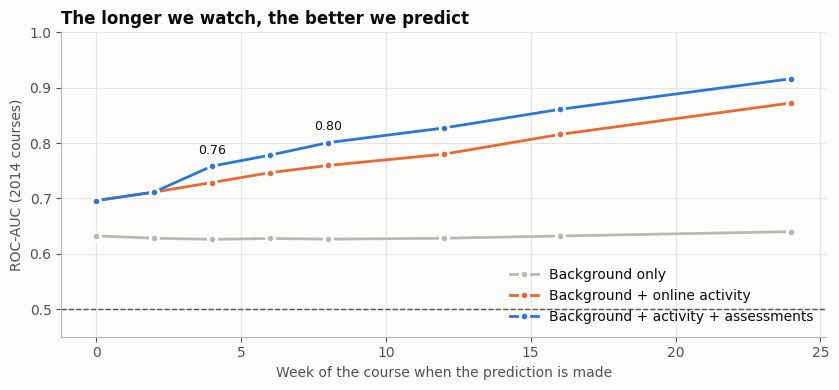

features,Background only,Background + online activity,Background + activity + assessments
day,,,
0,0.632,0.696,0.696
14,0.628,0.711,0.711
28,0.626,0.729,0.758
42,0.628,0.746,0.778
56,0.626,0.759,0.801
84,0.628,0.780,0.827
112,0.632,0.815,0.861
168,0.640,0.872,0.916


In [4]:
nc = results[results["target"] == "not_completed"].pivot(index="day", columns="features", values="ROC-AUC")[list(FEATURE_SETS)]
fig, ax = plt.subplots(figsize=(8.5, 4))
colors = [style.NEUTRAL, style.ORANGE, style.BLUE]
for (name, col), c in zip(nc.items(), colors):
    ax.plot(nc.index / 7, col, marker="o", color=c, label=name, markeredgecolor=style.SURFACE, markeredgewidth=2)
for d in [28, 56]:
    ax.annotate(f"{nc.loc[d, list(FEATURE_SETS)[-1]]:.2f}", (d / 7, nc.loc[d, list(FEATURE_SETS)[-1]]),
                xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
ax.axhline(0.5, color=style.TEXT_2, lw=1, ls="--")
ax.set(ylim=(0.45, 1), xlabel="Week of the course when the prediction is made", ylabel="ROC-AUC (2014 courses)",
       title="The longer we watch, the better we predict")
ax.legend(loc="lower right")
save_fig("07_auc_over_time")
plt.show()
nc.round(3)

Three lessons:
- **Background alone is weak** (ROC-AUC about 0.63) and doesn't improve over time. Who a student is says much less than what they do.
- **Online activity** adds most of the signal, already at **day 0**: clicks before the course starts tell us something.
- **Assessments** add a further boost once the first deadline has passed (around day 22).

There is a **trade-off between early and accurate**: by week 8, predictions are good (ROC-AUC about 0.80), but some students are already gone. Notebook 01 showed that half of all withdrawals happen by day 27.

## 4. What would a tutor actually see?

Suppose a tutor has time to contact **1 in 5 students**: the 20% the model ranks as most at risk.

In [5]:
rows = []
for day in DAYS:
    s = snapshots[day]
    te = ~s["train"]
    y = s.loc[te, "not_completed"]
    p = preds[day].loc[y.index]
    flagged = p >= p.quantile(0.80)
    rows.append({"week": day // 7, "students": len(y), "% not completing": y.mean() * 100,
                 "% of flagged who don't complete (precision)": y[flagged].mean() * 100,
                 "% of non-completers flagged (recall)": y[flagged].sum() / y.sum() * 100})
tutor = pd.DataFrame(rows).set_index("week")
tutor.round(1)

,students,% not completing,% of flagged who don't complete (precision),% of non-completers flagged (recall)
week,,,,
0,17024,48.7,73.9,30.3
2,15985,44.9,72.6,32.3
4,15720,43.9,75.7,34.4
6,15398,42.8,76.7,35.9
8,15087,41.6,80.0,38.5
12,14589,39.6,82.0,41.5
16,14155,37.7,90.1,47.8
24,13315,33.8,96.4,57.0


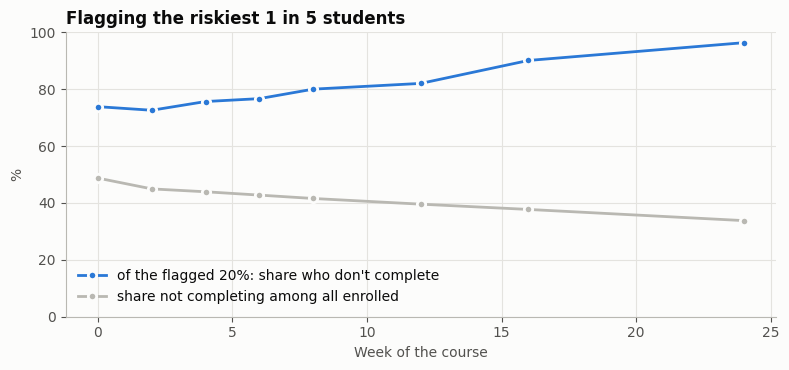

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(tutor.index, tutor["% of flagged who don't complete (precision)"], marker="o", color=style.BLUE,
        label="of the flagged 20%: share who don't complete", markeredgecolor=style.SURFACE, markeredgewidth=2)
ax.plot(tutor.index, tutor["% not completing"], marker="o", color=style.NEUTRAL,
        label="share not completing among all enrolled", markeredgecolor=style.SURFACE, markeredgewidth=2)
ax.set(ylim=(0, 100), xlabel="Week of the course", ylabel="%", title="Flagging the riskiest 1 in 5 students")
ax.legend(loc="lower left")
save_fig("08_tutor_view")
plt.show()

At **week 4**, about 3 in 4 of the flagged students go on not to complete, against about 44% of all enrolled students.
By **week 8**, it is about 8 in 10. Because so many students don't complete, flagging only 20% can't reach all of them: recall stays below half until week 16. The list should be read as **"who to call first"**, not as a complete list of everyone at risk.

## 5. What drives the predictions? (week 8)

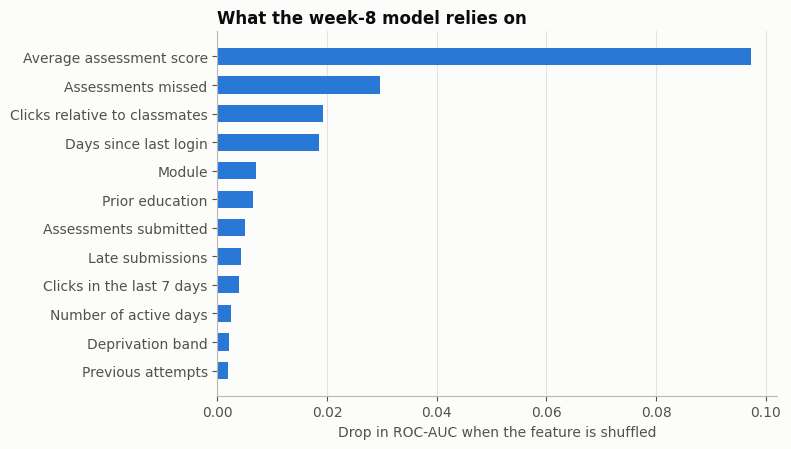

In [7]:
day = 56
s = snapshots[day]
tr, te = s["train"].to_numpy(), ~s["train"].to_numpy()
cols = CATEGORICAL + BACKGROUND + ACTIVITY + ASSESSMENT
m8 = model(BACKGROUND + ACTIVITY + ASSESSMENT).fit(s[tr], s.loc[tr, "not_completed"])
imp = permutation_importance(m8, s.loc[te, cols], s.loc[te, "not_completed"], scoring="roc_auc",
                             n_repeats=5, random_state=0, n_jobs=-1)
nice = {"clicks_total": "Total clicks so far", "clicks_last_7_days": "Clicks in the last 7 days",
        "days_since_last_active": "Days since last login", "active_days": "Number of active days",
        "clicks_vs_classmates": "Clicks relative to classmates", "assessments_submitted": "Assessments submitted",
        "assessments_missed": "Assessments missed", "mean_score": "Average assessment score",
        "late_submissions": "Late submissions", "code_module": "Module", "imd_band": "Deprivation band",
        "highest_education": "Prior education", "studied_credits": "Credits studied", "num_of_prev_attempts": "Previous attempts",
        "registered_days_early": "Days registered before start", "clicks_before_start": "Clicks before the course started",
        "clicks_quiz": "Clicks on quizzes", "clicks_forumng": "Clicks on forums", "clicks_oucontent": "Clicks on course content",
        "clicks_homepage": "Clicks on module homepage", "clicks_subpage": "Clicks on sub-pages", "clicks_resource": "Clicks on resources",
        "clicks_url": "Clicks on links", "clicks_ouwiki": "Clicks on wiki", "age_band": "Age", "gender": "Gender",
        "region": "Region", "disability": "Disability", "assessments_due": "Assessments due", "module_presentation_length": "Course length"}
top = pd.Series(imp.importances_mean, index=cols).sort_values(ascending=False).head(12).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh([nice.get(i, i) for i in top.index], top, color=style.BLUE, height=0.6)
ax.set(xlabel="Drop in ROC-AUC when the feature is shuffled", title="What the week-8 model relies on")
ax.grid(axis="y", visible=False)
save_fig("09_feature_importance")
plt.show()

The model mostly looks at **behaviour**: how much students have done and how good their work is (assessment scores and submissions), and how recently they were active.
Background features such as deprivation and prior education rank much lower. They matter on average (notebook 01), but once we can see what a student is actually doing, they add little.

## 6. Does it work on a course it has never seen?

In [8]:
y8 = s.loc[te, ["code_module", "not_completed"]].assign(p=preds[56])
per_module = y8.groupby("code_module").apply(
    lambda g: pd.Series({"students": len(g), "% not completing": g["not_completed"].mean() * 100,
                         "ROC-AUC": roc_auc_score(g["not_completed"], g["p"])}))
per_module["seen in training?"] = ["no (2014 only)" if m == "CCC" else "yes" for m in per_module.index]
per_module.round(3)

,students,% not completing,ROC-AUC,seen in training?
code_module,,,,
AAA,342.0,26.023,0.763,yes
BBB,2997.0,37.304,0.733,yes
CCC,3239.0,48.194,0.831,no (2014 only)
DDD,2388.0,46.817,0.834,yes
EEE,1583.0,34.239,0.829,yes
FFF,3050.0,41.934,0.842,yes
GGG,1488.0,38.038,0.713,yes


Performance ranges from about **0.71** (GGG) to **0.84** (FFF). **CCC**, which the model never saw in training, scores **0.83**, among the best. Behavioural signals such as logging in, submitting and scoring well transfer to new courses, which makes the approach practical for a university that keeps launching new modules.
The three social-science modules (AAA, BBB, GGG) are harder to predict. GGG, for example, has **no assessment due before week 8**, so the model has less to go on.

## 7. Is it fair across groups of students?

An early-warning model can be unfair in two ways: it can **flag one group much more often**, or its flags can be **less accurate for one group**. We check both at week 8, flagging the riskiest 20% of students.

In [9]:
g = s.loc[te].assign(p=preds[56])
g["flag_global"] = g["p"] >= g["p"].quantile(0.80)
g["flag_by_course"] = g.groupby(["code_module", "code_presentation"])["p"].transform(lambda x: x >= x.quantile(0.80))
g["deprivation"] = np.where(g["imd_band"].isin(["0-10%", "10-20%", "20-30%"]), "Most deprived 30%",
                    np.where(g["imd_band"] == "Unknown", "Unknown", "Other areas"))

def fairness(col, flag):
    rows = {}
    for key, d in g.groupby(col):
        rows[key] = {"students": len(d), "% not completing": d["not_completed"].mean() * 100,
                     "% flagged": d[flag].mean() * 100,
                     "precision": d.loc[d[flag], "not_completed"].mean() * 100,
                     "recall": d.loc[d["not_completed"] == 1, flag].mean() * 100}
    return pd.DataFrame(rows).T.round(1)

for col in ["deprivation", "disability", "gender"]:
    print(f"--- {col} (one ranking across all courses) ---")
    print(fairness(col, "flag_global").to_string(), "\n")

--- deprivation (one ranking across all courses) ---
                   students  % not completing  % flagged  precision  recall
Most deprived 30%    4579.0              49.4       25.1       83.1    42.2
Other areas          9913.0              38.8       18.3       78.0    36.7
Unknown               595.0              27.9        9.7       82.8    28.9 

--- disability (one ranking across all courses) ---
   students  % not completing  % flagged  precision  recall
N   13677.0              40.6       19.6       79.3    38.4
Y    1410.0              51.4       23.5       85.8    39.3 

--- gender (one ranking across all courses) ---
   students  % not completing  % flagged  precision  recall
F    6456.0              39.3       19.4       66.9    33.0
M    8631.0              43.3       20.4       89.3    42.2 



- **Deprivation and disability:** students from the most deprived areas and disabled students are flagged more often, which matches their higher real risk. Their flags are at least as accurate as everyone else's.
- **Gender:** here there is a real gap. Only **67%** of flagged women go on not to complete, against **89%** of flagged men. The model also catches fewer of the women who don't complete (33% vs 42%).

Is the model biased against women? Looking deeper, the gap comes from **which courses** women and men take:

In [10]:
mix = (pd.crosstab(g["code_module"], g["gender"], normalize="index") * 100).round(0).rename(columns={"F": "% women", "M": "% men"})
per_course = pd.DataFrame({m: {"% flagged": d["flag_global"].mean() * 100,
                               "precision": d.loc[d["flag_global"], "not_completed"].mean() * 100,
                               "% not completing": d["not_completed"].mean() * 100}
                           for m, d in g.groupby("code_module")}).T.round(1)
mix.join(per_course)

,% women,% men,% flagged,precision,% not completing
code_module,,,,,
AAA,43.0,57.0,6.4,77.3,26.0
BBB,88.0,12.0,30.4,55.0,37.3
CCC,24.0,76.0,26.6,88.0,48.2
DDD,39.0,61.0,20.2,91.1,46.8
EEE,12.0,88.0,12.8,96.0,34.2
FFF,18.0,82.0,17.7,93.7,41.9
GGG,80.0,20.0,0.0,NaN,38.0


- Women are **88% of BBB** and **80% of GGG**. In BBB the model **over-flags** (30% of students, of whom only 55% don't complete). In GGG it **never flags anyone**: with no assessments yet, no GGG student's risk score reaches the global top 20%, even though 38% of them won't complete.
- Within the STEM modules, flagged women and men are equally likely not to complete (about 91% each).

So the gender gap is really a **course gap**. Risk scores aren't equally comparable across courses, and one ranking for the whole university mixes them up.

**The fix is also how a tutor would work: flag the riskiest 20% within each course.**

In [11]:
compare = []
for col in ["gender", "deprivation", "disability"]:
    a, b = fairness(col, "flag_global"), fairness(col, "flag_by_course")
    for key in a.index:
        compare.append({"group": f"{col}: {key}", "precision (one ranking)": a.loc[key, "precision"],
                        "precision (by course)": b.loc[key, "precision"],
                        "recall (one ranking)": a.loc[key, "recall"], "recall (by course)": b.loc[key, "recall"]})
compare = pd.DataFrame(compare).set_index("group")
for flag in ["flag_global", "flag_by_course"]:
    print(f"{flag}: overall precision {g.loc[g[flag], 'not_completed'].mean():.0%}, "
          f"recall {g.loc[g['not_completed'] == 1, flag].mean():.0%}")
compare

flag_global: overall precision 80%, recall 38%
flag_by_course: overall precision 84%, recall 40%


,precision (one ranking),precision (by course),recall (one ranking),recall (by course)
group,,,,
gender: F,66.9,78.0,33.0,37.7
gender: M,89.3,87.7,42.2,42.2
deprivation: Most deprived 30%,83.1,85.1,42.2,45.9
deprivation: Other areas,78.0,82.7,36.7,37.7
deprivation: Unknown,82.8,86.5,28.9,27.1
disability: N,79.3,83.5,38.4,39.7
disability: Y,85.8,85.5,39.3,45.4


Ranking within each course:
- **narrows the gender gap** in precision (from 67% vs 89% to 78% vs 88%) and in recall (33% vs 42% becomes 38% vs 42%);
- gives **GGG students** flags they never got before;
- slightly **improves the model overall** (precision 80% to 84%, recall 38% to 40%).

A smaller gap remains, from the harder-to-predict social-science modules. Fairness is also a question of **what happens after the flag**: extra support is welcome, while extra pressure or reduced opportunities would not be. Any real deployment needs that conversation with students and staff.

## Conclusions
1. **Predict "not completing", not just withdrawal.** Many students disengage silently and fail. A withdrawal-only model misses them and looks much worse.
2. **Behaviour beats background.** Background alone gives ROC-AUC about 0.63. Online activity and assessments raise it to about 0.76 at week 4 and 0.80 at week 8.
3. **Early vs accurate is a real trade-off.** Half of withdrawals happen by day 27, so waiting for better predictions means losing students.
4. **It is practical.** At week 8, about 8 in 10 of the riskiest fifth of students don't complete, and the model works on a module it has never seen.
5. **Check fairness, and look beneath it.** An apparent gender gap in flag accuracy turned out to be a course effect. Ranking students within each course fixes most of it and improves the model too.

## Limitations and next steps
- Data from one university in 2013–2014. Online learning has changed a lot since.
- Clicks are a crude measure of learning: a student may study from downloaded or printed material.
- **Next:** model *time to dropout* with survival analysis, use week-by-week activity sequences (for example with recurrent networks), and measure whether contacting flagged students actually changes outcomes. That needs an experiment, not just a model.